In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import os
print(torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No hay GPU disponible. Activala en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")

True
PyTorch: 2.6.0+cu124
Torchvision: 0.21.0+cu124
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3080
VRAM: 10.0 GB


In [2]:
import os
import torch
import torchvision
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

image_dir = "fifa/Images"
data = pd.read_csv("fifa/data.csv")

# Conservar únicamente imágenes que Pillow pueda abrir
valid_paths = []

for filename in os.listdir(image_dir):
    path = os.path.join(image_dir, filename)

    if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".webp")):
        continue

    try:
        with Image.open(path) as img:
            img.verify()
        valid_paths.append(path)
    except Exception:
        continue

# Orden numérico, como en el código original
valid_paths.sort(
    key=lambda p: int(os.path.splitext(os.path.basename(p))[0])
)

print("Imágenes válidas:", len(valid_paths))


class FIFADataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
        self.transform = transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5]
            )
        ])

    def __len__(self):
            return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            rgba = im.convert("RGBA")

        # Componer sobre negro usando transparencia real
        background = Image.new("RGBA", rgba.size, (0, 0, 0, 255))
        rgb = Image.alpha_composite(background, rgba).convert("RGB")

        return self.transform(rgb)

dataset = FIFADataset(valid_paths)
print("Cantidad de imágenes:", len(dataset))
print("Forma:", dataset[0].shape)

Imágenes válidas: 15234
Cantidad de imágenes: 15234
Forma: torch.Size([3, 128, 128])


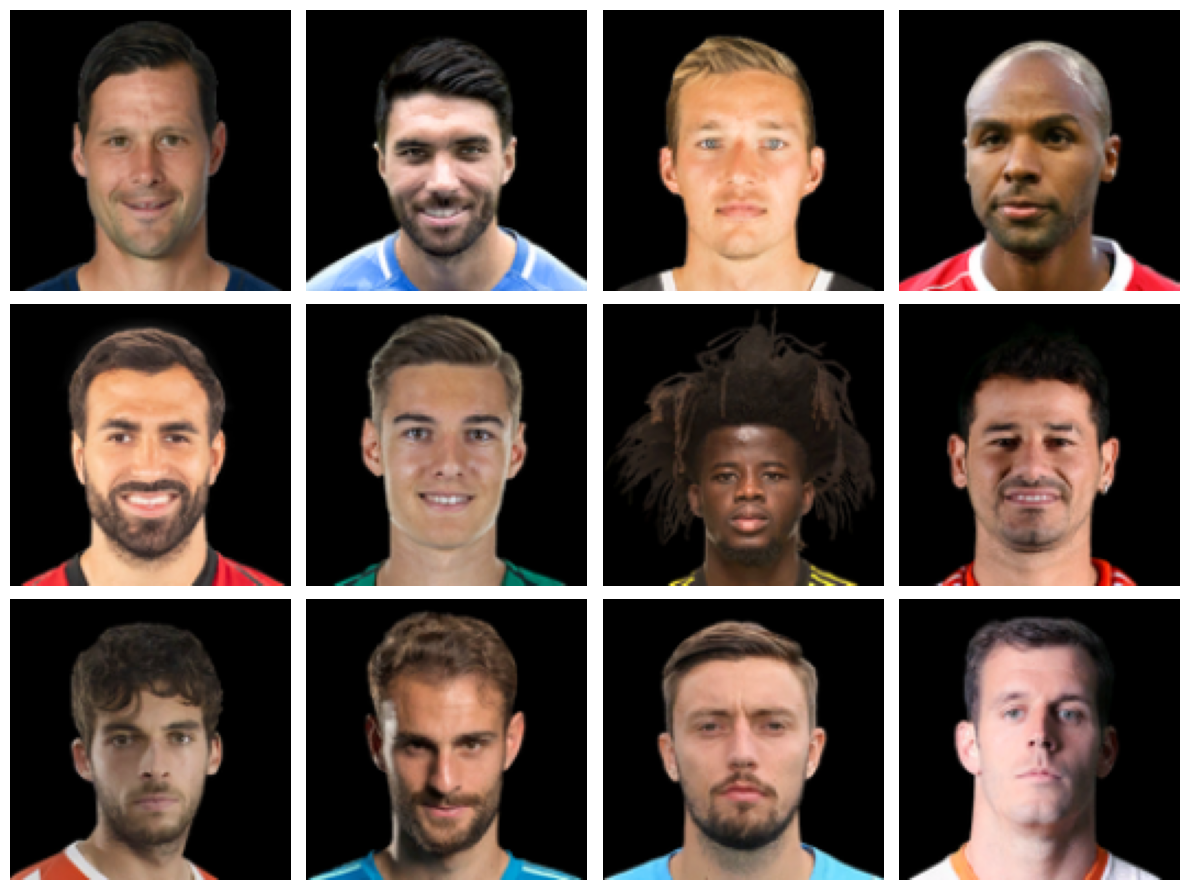

In [3]:
import matplotlib.pyplot as plt
import random

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, idx in zip(
    axes.flat,
    random.sample(range(len(dataset)), 12)
):
    img = dataset[idx]
    img = (img * 0.5 + 0.5).clamp(0, 1)

    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class GeneratorBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, padding=1
        )

        self.bn2 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, padding=1
        )

        self.skip = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x):
        residual = F.interpolate(x, scale_factor=2, mode="nearest")

        out = self.bn1(x)
        out = F.relu(out)
        out = F.interpolate(out, scale_factor=2, mode="nearest")
        out = self.conv1(out)

        out = self.bn2(out)
        out = F.relu(out)
        out = self.conv2(out)

        return out + self.skip(residual)


class Generator(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.latent_dim = latent_dim

        self.fc = nn.Linear(latent_dim, 4 * 4 * 512)

        self.blocks = nn.Sequential(
            GeneratorBlock(512, 256),  # 8x8
            GeneratorBlock(256, 128),  # 16x16
            GeneratorBlock(128, 64),   # 32x32
            GeneratorBlock(64, 32),    # 64x64
            GeneratorBlock(32, 32),    # 128x128
        )

        self.to_rgb = nn.Sequential(
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 3, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(z.size(0), 512, 4, 4)
        x = self.blocks(x)
        return self.to_rgb(x)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 128
G = Generator(latent_dim).to(device)

import copy

G_ema = copy.deepcopy(G).eval()

for p in G_ema.parameters():
    p.requires_grad_(False)

ema_decay = 0.995


@torch.no_grad()
def update_ema():
    for p_ema, p in zip(G_ema.parameters(), G.parameters()):
        p_ema.lerp_(p, 1 - ema_decay)

    for b_ema, b in zip(G_ema.buffers(), G.buffers()):
        b_ema.copy_(b)

z = torch.randn(4, latent_dim, device=device)
fake_images = G(z)

print("Entrada:", z.shape)
print("Salida:", fake_images.shape)
print("Dispositivo:", device)

Entrada: torch.Size([4, 128])
Salida: torch.Size([4, 3, 128, 128])
Dispositivo: cuda


In [6]:
class DiscriminatorBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.utils.spectral_norm(
            nn.Conv2d(in_channels, out_channels, 3, padding=1)
        )
        self.conv2 = nn.utils.spectral_norm(
            nn.Conv2d(out_channels, out_channels, 3, padding=1)
        )

        self.skip = nn.utils.spectral_norm(
            nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x):
        residual = F.avg_pool2d(self.skip(x), 2)

        out = F.relu(x)
        out = self.conv1(out)
        out = F.relu(out)
        out = self.conv2(out)
        out = F.avg_pool2d(out, 2)

        return (out + residual) / 2**0.5


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.from_rgb = nn.utils.spectral_norm(
            nn.Conv2d(3, 64, kernel_size=3, padding=1)
        )

        self.blocks = nn.Sequential(
            DiscriminatorBlock(64, 128),   # 64x64
            DiscriminatorBlock(128, 256),  # 32x32
            DiscriminatorBlock(256, 512),  # 16x16
            DiscriminatorBlock(512, 512),  # 8x8
        )

        self.final = nn.Sequential(
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(512 * 8 * 8, 1)
        )

    def forward(self, x):
        x = self.from_rgb(x)
        x = self.blocks(x)
        return self.final(x).squeeze(1)

In [7]:
D = Discriminator().to(device)

real_batch = torch.randn(4, 3, 128, 128, device=device)
scores = D(real_batch)

print("Entrada:", real_batch.shape)
print("Salida:", scores.shape)
print("Parámetros G:", sum(p.numel() for p in G.parameters()))
print("Parámetros D:", sum(p.numel() for p in D.parameters()))

Entrada: torch.Size([4, 3, 128, 128])
Salida: torch.Size([4])
Parámetros G: 3604803
Parámetros D: 9836417


In [8]:
import torch.optim as optim

lr = 0.0001
beta1 = 0.0
beta2 = 0.9

optimizer_G = optim.Adam(
    G.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

optimizer_D = optim.Adam(
    D.parameters(),
    lr=0.00005,
    betas=(beta1, beta2)
)


def discriminator_loss(real_scores, fake_scores):
    loss_real = torch.relu(1.0 - real_scores).mean()
    loss_fake = torch.relu(1.0 + fake_scores).mean()
    return loss_real + loss_fake


def generator_loss(fake_scores):
    return -fake_scores.mean()


print("Optimizadores y funciones de pérdida configurados.")

Optimizadores y funciones de pérdida configurados.


In [9]:
# checkpoint = torch.load(
#     "gan_checkpoint.pth",
#     map_location=device,
#     weights_only=False
# )

# G.load_state_dict(checkpoint["G"])
# D.load_state_dict(checkpoint["D"])

# if "G_ema" in checkpoint:
#     G_ema.load_state_dict(checkpoint["G_ema"])
# else:
#     G_ema.load_state_dict(G.state_dict())

# G_ema.eval()

# optimizer_G.load_state_dict(checkpoint["optimizer_G"])
# optimizer_D.load_state_dict(checkpoint["optimizer_D"])

# history_G = checkpoint["history_G"]
# history_D = checkpoint["history_D"]

# start_epoch = checkpoint["epoch"] + 1

# print("Última época:", checkpoint["epoch"])
# print("Continuaremos desde:", start_epoch)

In [10]:
import time
from torch.utils.data import DataLoader
print("Probando acceso")
t0=time.time()

img=dataset[0]

print(img.shape)
print(round(time.time() - t0),2)

t0=time.time()

dataloader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    drop_last=True
)



Probando acceso
torch.Size([3, 128, 128])
0 2


In [11]:
real_images = next(iter(dataloader)).to(device)

print(real_images.device)
print("Lote:", real_images.shape)
print("Rango:", real_images.min().item(), real_images.max().item())

cuda:0
Lote: torch.Size([32, 3, 128, 128])
Rango: -1.0 1.0


In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs("gan_samples", exist_ok=True)

fixed_noise = torch.randn(16, latent_dim, device=device)

def show_samples(epoch):
    G.eval()
    G_ema.eval()

    with torch.no_grad():
        samples_g = G(fixed_noise).cpu()
        samples_ema = G_ema(fixed_noise).cpu()

    print(
        "Diferencia media G:",
        torch.pdist(samples_g.flatten(1)).mean().item()
    )
    print(
        "Diferencia media G_ema:",
        torch.pdist(samples_ema.flatten(1)).mean().item()
    )

    samples = (samples_ema * 0.5 + 0.5).clamp(0, 1)

    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for ax, img in zip(axes.flat, samples):
        ax.imshow(img.permute(1, 2, 0))
        ax.axis("off")

    plt.suptitle(f"Época {epoch}")
    plt.tight_layout()
    plt.savefig(f"gan_samples/epoch_{epoch:03d}.png")
    plt.show()

G.train()

Generator(
  (fc): Linear(in_features=128, out_features=8192, bias=True)
  (blocks): Sequential(
    (0): GeneratorBlock(
      (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(512, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (skip): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    )
    (1): GeneratorBlock(
      (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (skip): Conv2d(256, 128, kernel_size=(1, 1), stride=(1, 1))
    )
 

In [ ]:
from tqdm.auto import tqdm

epochs = 60

history_D = []
history_G = []

for epoch in range(1, epochs+1):
#for epoch in range(1, epochs + 1):
    G.train()
    D.train()

    total_G = 0.0
    total_D = 0.0

    progress = tqdm(dataloader, desc=f"Época {epoch}/{epochs}")

    for real_images in progress:
        real_images = real_images.to(device, non_blocking=True)
        batch = real_images.size(0)

        # Entrenar discriminador
        optimizer_D.zero_grad(set_to_none=True)

        noise = torch.randn(batch, latent_dim, device=device)

        with torch.no_grad():
            fake_images = G(noise)

        real_scores = D(real_images)
        fake_scores = D(fake_images)

        loss_D = discriminator_loss(real_scores, fake_scores)
        loss_D.backward()
        optimizer_D.step()

        # Entrenar generador
        optimizer_G.zero_grad(set_to_none=True)

        noise = torch.randn(batch, latent_dim, device=device)
        fake_images = G(noise)
        fake_scores = D(fake_images)
        
        loss_G = generator_loss(fake_scores)
        loss_G.backward()
        optimizer_G.step()
        update_ema()
        total_D += loss_D.item()
        total_G += loss_G.item()

        progress.set_postfix(
            D=f"{loss_D.item():.3f}",
            G=f"{loss_G.item():.3f}"
        )

    avg_D = total_D / len(dataloader)
    avg_G = total_G / len(dataloader)

    history_D.append(avg_D)
    history_G.append(avg_G)

    print(
        f"Época {epoch}: "
        f"D={avg_D:.4f} | G={avg_G:.4f}"
    )

    show_samples(epoch)

    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "G_ema": G_ema.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "history_G": history_G,
        "history_D": history_D
    }, "gan_checkpoint.pth")
    
    with torch.no_grad():
        samples = G(torch.randn(64, latent_dim, device=device))
    
    samples = samples.flatten(1)
    distances = torch.pdist(samples)

    print("Distancia mínima:", distances.min().item())
    print("Distancia media:", distances.mean().item())
    print("Distancia máxima:", distances.max().item())